# 06 - Correlation Pairs

Turns the correlation matrix into a long table: one row per (ticker pair, window, date). A matrix cannot be loaded into SQL or Power BI as a relationship; a long table can.

**Correlation** measures how much two stocks move together on the same day: +1 move together, 0 unrelated, -1 move in opposite directions. Low correlation between holdings is what makes a mix of stocks less risky than its parts.

| Column | Meaning |
|---|---|
| `ticker_a`, `ticker_b` | The pair. Both orders (AAPL-MSFT and MSFT-AAPL) and the diagonal (AAPL-AAPL = 1) are stored |
| `window_type` | `full` = all daily returns 2021-2025 (the same numbers as `correlation_matrix.csv`); `rolling_60d` = the last 60 daily returns |
| `as_of_date` | The date the correlation is measured at. `full`: the last trading day. `rolling_60d`: the last trading day of each month (the same dates as `risk_monthly.csv`) |
| `correlation` | Pearson correlation of daily simple returns |

**Output:** `data/processed/correlation_pairs.csv`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# Find the project root (the folder that contains "src")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "risk").exists())
sys.path.insert(0, str(ROOT))

from src.risk import risk_metrics as rm

RAW_FILE = ROOT / "data" / "raw" / "yahoo_prices_raw.csv"
MATRIX_FILE = ROOT / "data" / "processed" / "correlation_matrix.csv"
OUT_FILE = ROOT / "data" / "processed" / "correlation_pairs.csv"
ROLLING_WINDOW = 60   # trading days (about 3 months)
print("Project root:", ROOT)

Project root: d:\DEPI\MarketPulse Graduation Project


## 1. Daily returns

In [2]:
prices = rm.load_prices(RAW_FILE)
returns = rm.compute_returns(prices)   # same returns the risk engine uses
print("Returns:", returns.shape, "|", returns.index.min().date(), "->", returns.index.max().date())

Returns: (1253, 10) | 2021-01-05 -> 2025-12-30


## 2. Full-period correlation

Computed once on all returns. This is the matrix from `04_risk_engine`, written as pairs.

In [3]:
def to_pairs(corr, window_type, as_of_date):
    out = corr.rename_axis(index="ticker_a", columns="ticker_b").stack().rename("correlation").reset_index()
    out.insert(2, "window_type", window_type)
    out.insert(3, "as_of_date", as_of_date)
    return out[["ticker_a", "ticker_b", "window_type", "as_of_date", "correlation"]]


full = to_pairs(returns.corr(), "full", returns.index.max())
print(len(full), "rows")
full.head()

100 rows


,ticker_a,ticker_b,window_type,as_of_date,correlation
0,AAPL,AAPL,full,2025-12-30,1.000000
1,AAPL,AMZN,full,2025-12-30,0.561269
2,AAPL,JNJ,full,2025-12-30,0.154077
3,AAPL,JPM,full,2025-12-30,0.345375
4,AAPL,KO,full,2025-12-30,0.271231


## 3. Rolling 60-day correlation

At the last trading day of each month, correlate the previous 60 daily returns. The first one is March 2021, the first month-end with 60 returns. Correlation changes over time, and it usually rises in crises: stocks fall together just when diversification is needed most.

In [4]:
month_ends = returns.groupby(returns.index.to_period("M")).tail(1).index
rolling_parts = []
for d in month_ends:
    window = returns.loc[:d].tail(ROLLING_WINDOW)
    if len(window) < ROLLING_WINDOW:
        continue                      # not enough history yet
    rolling_parts.append(to_pairs(window.corr(), "rolling_60d", d))
rolling = pd.concat(rolling_parts, ignore_index=True)
print(len(rolling), "rows |", rolling["as_of_date"].nunique(), "month-ends |",
      rolling["as_of_date"].min().date(), "->", rolling["as_of_date"].max().date())

5800 rows | 58 month-ends | 2021-03-31 -> 2025-12-30


In [5]:
pairs = pd.concat([full, rolling], ignore_index=True)
pairs = pairs.sort_values(["window_type", "as_of_date", "ticker_a", "ticker_b"]).reset_index(drop=True)
pairs.head(12)

,ticker_a,ticker_b,window_type,as_of_date,correlation
0,AAPL,AAPL,full,2025-12-30,1.000000
1,AAPL,AMZN,full,2025-12-30,0.561269
2,AAPL,JNJ,full,2025-12-30,0.154077
3,AAPL,JPM,full,2025-12-30,0.345375
4,AAPL,KO,full,2025-12-30,0.271231
5,AAPL,LLY,full,2025-12-30,0.193029
6,AAPL,MSFT,full,2025-12-30,0.633926
7,AAPL,NVDA,full,2025-12-30,0.519824
8,AAPL,TSLA,full,2025-12-30,0.500155
9,AAPL,XOM,full,2025-12-30,0.189346


## 4. Checks

In [6]:
tickers = sorted(returns.columns)
n = len(tickers)
matrix = pd.read_csv(MATRIX_FILE, index_col=0) if MATRIX_FILE.exists() else None
full_matrix = pairs[pairs["window_type"] == "full"].pivot(index="ticker_a", columns="ticker_b", values="correlation")
roll = pairs[pairs["window_type"] == "rolling_60d"]
months = roll["as_of_date"].nunique()

# the same pair in both orders must have the same value
swap = pairs.rename(columns={"ticker_a": "ticker_b", "ticker_b": "ticker_a"})
both = pairs.merge(swap, on=["ticker_a", "ticker_b", "window_type", "as_of_date"], suffixes=("", "_swap"))

checks = {
    "Columns match the proposed table": list(pairs.columns) == ["ticker_a", "ticker_b", "window_type", "as_of_date", "correlation"],
    "PK (ticker_a, ticker_b, window_type, as_of_date) is unique": not pairs.duplicated(["ticker_a", "ticker_b", "window_type", "as_of_date"]).any(),
    "Full window has 100 rows (10 x 10)": int((pairs["window_type"] == "full").sum()) == n * n,
    "Every rolling date has 100 rows": bool((roll.groupby("as_of_date").size() == n * n).all()),
    "No missing values": not pairs.isna().any().any(),
    "Correlations are within [-1, 1]": bool(pairs["correlation"].between(-1, 1).all()),
    "Diagonal is 1": bool(np.allclose(pairs.loc[pairs["ticker_a"] == pairs["ticker_b"], "correlation"], 1)),
    "A-B equals B-A": bool(np.allclose(both["correlation"], both["correlation_swap"])),
    "Rolling dates are month-ends of risk_monthly (58 months from 2021-03)": months == 58 and roll["as_of_date"].min().strftime("%Y-%m") == "2021-03",
    "Full window matches correlation_matrix.csv": True if matrix is None else bool(np.allclose(full_matrix.values, matrix.loc[full_matrix.index, full_matrix.columns].values, atol=1e-5)),
}
pd.Series(checks, name="passed").to_frame()

,passed
Columns match the proposed table,True
"PK (ticker_a, ticker_b, window_type, as_of_date) is unique",True
Full window has 100 rows (10 x 10),True
Every rolling date has 100 rows,True
No missing values,True
"Correlations are within [-1, 1]",True
Diagonal is 1,True
A-B equals B-A,True
Rolling dates are month-ends of risk_monthly (58 months from 2021-03),True
Full window matches correlation_matrix.csv,True


## 5. Charts

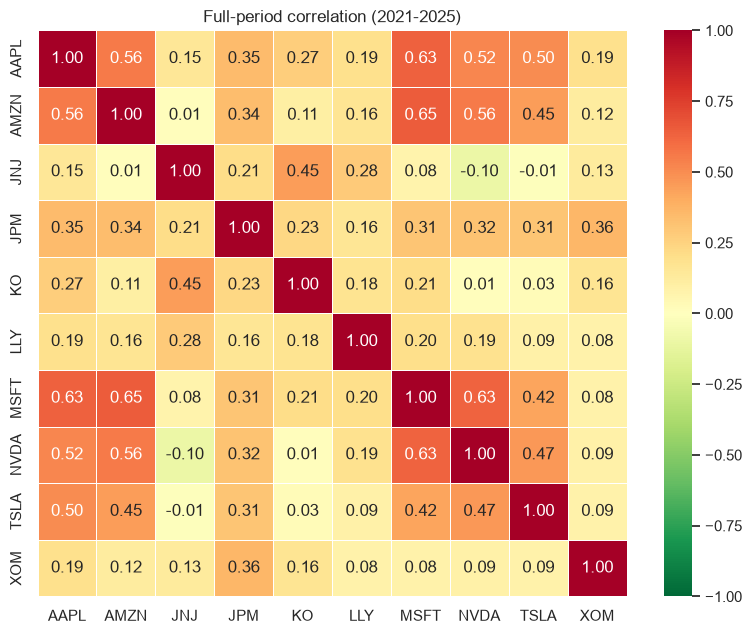

In [7]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(full_matrix, annot=True, fmt=".2f", cmap="RdYlGn_r", vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Full-period correlation (2021-2025)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

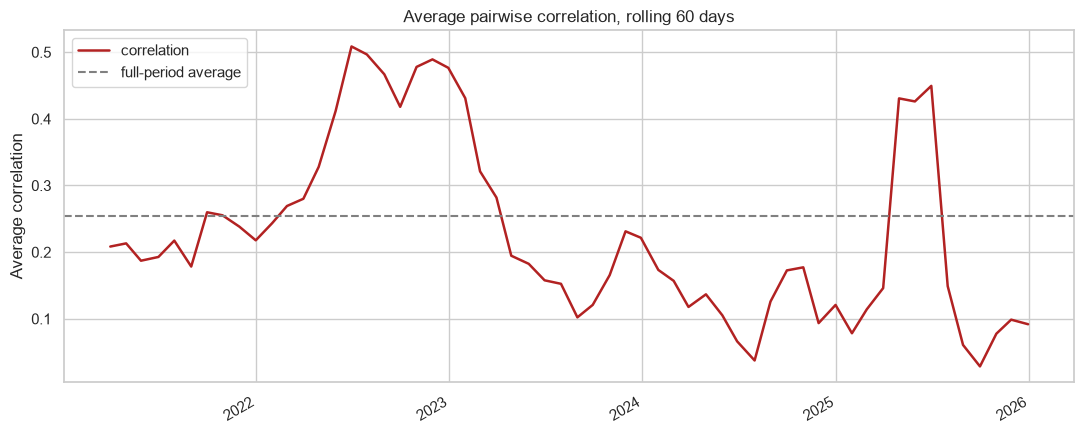

In [8]:
off = roll[roll["ticker_a"] < roll["ticker_b"]]          # each pair once, no diagonal
avg = off.groupby("as_of_date")["correlation"].mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
avg.plot(ax=ax, color="firebrick", linewidth=1.8)
ax.axhline(full.loc[full["ticker_a"] < full["ticker_b"], "correlation"].mean(), color="grey", linestyle="--", label="full-period average")
ax.set_title("Average pairwise correlation, rolling 60 days")
ax.set_ylabel("Average correlation"); ax.set_xlabel("")
ax.legend()
plt.tight_layout(); plt.show()

## 6. Key observations

In [9]:
once = full[full["ticker_a"] < full["ticker_b"]].sort_values("correlation")
hi, lo = once.iloc[-1], once.iloc[0]
print(f"- Most correlated pair: {hi.ticker_a}-{hi.ticker_b} ({hi.correlation:.2f}); least correlated: {lo.ticker_a}-{lo.ticker_b} ({lo.correlation:.2f}).")
print(f"- Average pairwise correlation over the full period: {once['correlation'].mean():.2f}.")
print(f"- Rolling 60-day average ranges from {avg.min():.2f} ({avg.idxmin().strftime('%Y-%m')}) to {avg.max():.2f} ({avg.idxmax().strftime('%Y-%m')}).")

- Most correlated pair: AMZN-MSFT (0.65); least correlated: JNJ-NVDA (-0.10).
- Average pairwise correlation over the full period: 0.25.
- Rolling 60-day average ranges from 0.03 (2025-09) to 0.51 (2022-06).


## 7. Save

In [10]:
out = pairs.copy()
out["as_of_date"] = out["as_of_date"].dt.strftime("%Y-%m-%d")
OUT_FILE.parent.mkdir(parents=True, exist_ok=True)
out.to_csv(OUT_FILE, index=False)
print("Saved:", OUT_FILE, "|", len(out), "rows")

Saved: d:\DEPI\MarketPulse Graduation Project\data\processed\correlation_pairs.csv | 5900 rows
